# 22 · Global FTW: discover fields, probabilities and confidence

**Time:** 35 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** find the correct FTW product; inspect the three model classes; explain what a field prediction means.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=22_ftw_discovery.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. What kind of field is this?

**Global Fields of the World (FTW)** maps predicted agricultural field boundaries for 2024 and 2025.
The PRUE model uses Sentinel-2 planting and harvest composites. A connected predicted field interior is a
remote-sensing unit: it is **not a legal parcel, ownership record, crop label, or yield measurement**.
The earlier *Fields of the World training benchmark* is a separate dataset; these global predictions are not ground truth.

![Sentinel-2 composites lead to three probabilities, predicted polygons, and a separate confidence layer; independent evidence is required for impacts](assets/ftw-workflow.svg)

This studio uses two small African windows: the Senegal River valley and western Kenya. Each contains
128 × 128 contiguous native pixels, with all three probability classes and both years. These chosen windows
do not represent either country's farming systems. A roughly 10 m pixel is a model grid cell, not a promise of 10 m boundary accuracy.

**Predict:** can a sharp outline establish who farms the land? Name the independent evidence you would need.

In [2]:
from ftw import load_ftw, raster_map
d=load_ftw('senegal')  # repeat with 'kenya'
p=d['probability']
print(d['region']['title'])
print('Axes: year, class, row, column:',p.shape)
print('Years:',d['years'],'| classes:',d['bands'])
print('Pixel-edge bounding box:',d['region']['bounds'])
print('License:',d['provenance']['license'])
print('Source catalog commit:',d['provenance']['catalog_commit'])

Senegal River valley teaching window
Axes: year, class, row, column: (2, 3, 128, 128)
Years: [2024, 2025] | classes: ['non_field_background', 'field', 'field_boundaries']
Pixel-edge bounding box: [-16.22577813203939, 16.294277934016396, -16.21427973866979, 16.305776327385995]
License: CC-BY-4.0
Source catalog commit: fd844c4c646af0f8e653fba774f79cc17b2af124


## 2. Read a catalog before reading a planet

The bundled metadata is a pinned copy of the official STAC catalog. Catalogs describe assets; they do not
make every format directly readable in every browser. Inspect the Zarr array's dimensions and codecs.
Its full-resolution array uses sharded Zarr v3. Native preparation reads only the needed chunks;
our browser receives small NPZ extracts and uncompressed Zarr v2 teaching cubes.

| Product | Meaning | Useful question |
|---|---|---|
| Three ~10 m probability classes | Model softmax outputs | Which class is favored here? |
| Field polygons | Predicted field units | What sizes and shapes were delineated? |
| 500 m confidence / polygon score | Separate regional reliability model | How sensitive is a result to a quality filter? |

The metadata commit pins documentation. It does **not** freeze cloud data. Source ETags and extract checksums
record the retrieved objects and the exact classroom files.

In [3]:
catalog=json.loads((DATA/'ftw-catalog.json').read_text())
metadata=json.loads((DATA/'ftw-zarr-metadata.json').read_text())
a=metadata['consolidated_metadata']['metadata']['variables']
print('Catalog:',catalog['id'])
print('Global shape:',a['shape'],'| dtype:',a['data_type'])
print('Shard shape:',a['chunk_grid']['configuration']['chunk_shape'])
print('Codec:',a['codecs'][0]['name'])
global_bytes=int(np.prod(a['shape'],dtype=np.int64))*4
print(f'Uncompressed logical probability array: {global_bytes/1e12:.1f} TB')
print(f'This window, decoded probabilities: {p.nbytes/1e6:.2f} MB')
print('Transfer size also depends on source chunks, compression and request overhead.')

Catalog: ftw-global-data
Global shape: [2, 3, 1566049, 4007517] | dtype: float32
Shard shape: [1, 3, 8192, 8192]
Codec: sharding_indexed
Uncompressed logical probability array: 150.6 TB
This window, decoded probabilities: 0.39 MB
Transfer size also depends on source chunks, compression and request overhead.


## 3. Three classes, one probability budget

At each valid pixel the three probabilities sum approximately to one. A high boundary score can coexist
with a low field-interior score in a small field. These are model scores; they have not become calibrated
probabilities of ownership, productivity, or food insecurity. Missing predictions remain missing.

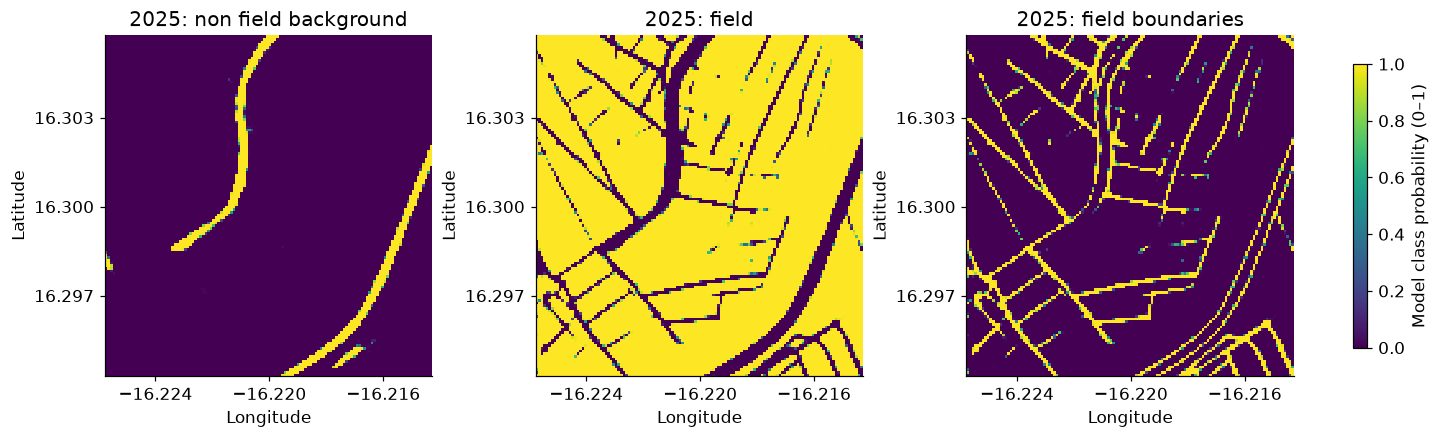

Valid pixel-years: 32768 of 32768
Mean class scores: [0.039 0.833 0.129]


In [4]:
valid=np.isfinite(p).all(axis=1)
np.testing.assert_allclose(p.sum(axis=1)[valid],1,atol=2e-6)
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for b,ax in enumerate(axes):
    image=raster_map(ax,d,p[1,b],f"2025: {d['bands'][b].replace('_',' ')}")
fig.colorbar(image,ax=axes,label='Model class probability (0–1)',shrink=.7)
plt.show()
print('Valid pixel-years:',int(valid.sum()),'of',valid.size)
print('Mean class scores:',np.round(np.nanmean(p,axis=(0,2,3)),3))

## 4. Browse beyond this sample

Open [FTW on Source Cooperative](https://source.coop/ftw/global-data) or the
[Portolan STAC browser](https://browser.portolan-sdi.org/#/external/data.source.coop/ftw/global-data/catalog.json).
Find the vector collection, a country partition, its GeoParquet asset, PMTiles map and style.
Record the year, license and product type before comparing it with this sample. External browsers need network access;
the numerical exercises run from bundled files after JupyterLite loads.

The optional native refresh command is `python scripts/prepare_ftw.py --fetch`, after installing
`requirements-ftw.txt` in a separate native Python environment. It is not a JupyterLite cell.
The source country files can be large: the script requires HTTP ranges, spatial row-group statistics and a byte budget.

## Try it yourself

Repeat with Kenya. Compare the three class distributions and explain why boundary-heavy pixels do not prove poor farming conditions.

## Check your reasoning

A model output describes a learned image pattern. Field identity, land rights, agricultural performance and household welfare require other evidence.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [Global Fields of the World on Source Cooperative](https://source.coop/ftw/global-data), Taylor Geospatial and collaborators, CC-BY-4.0.
- [Robinson et al. (2026), The first global agricultural field boundary map at 10 m resolution](https://doi.org/10.48550/arXiv.2605.11055).
- [Pinned official FTW catalog and product documentation](https://github.com/fieldsoftheworld/ftw-data-catalog/tree/fd844c4c646af0f8e653fba774f79cc17b2af124/catalog). PRUE model predictions use Copernicus Sentinel-2 composites.
- [Exact extracts, source ETags, spatial selection and SHA256 checksums](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/ftw-provenance.json). Local modifications: spatial subsets, GeoJSON conversion and scalar Zarr repackaging; original class values and full selected polygon geometries retained.

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [5]:
print('LESSON COMPLETE: 22_ftw_discovery')

LESSON COMPLETE: 22_ftw_discovery
